#importing libraries

In [26]:
import numpy as np
from tensorflow.keras import models , layers , datasets , utils 
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import seaborn as sns

#loading data  and saving

In [10]:

(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

X = np.concatenate((x_train, x_test), axis=0)
y= np.concatenate((y_train, y_test), axis=0)

np.savez_compressed("CIFAR10_full.npz", X=X, y=y)

print(X.shape)
print(y.shape)  


(60000, 32, 32, 3)
(60000, 1)


#loading saved data

In [11]:
data = np.load("CIFAR10_full.npz")

X = data["X"]
y = data["y"]

#train ad test split

In [12]:
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.2 , random_state=42, stratify= y)

print(f"X_train shape : {X_train.shape}")
print(f"y_train shape : {y_train.shape}")
print(f"X_test shape : {X_test.shape}")
print(f"y_test shape : {y_test.shape}")


X_train shape : (48000, 32, 32, 3)
y_train shape : (48000, 1)
X_test shape : (12000, 32, 32, 3)
y_test shape : (12000, 1)


#Encoding

In [13]:
#y_train = utils.to_categorical(y_train)
#y_test = utils.to_categorical(y_test)

#print(f"X_train shape : {X_train.shape}")
#print(f"y_train shape : {y_train.shape}")
#print(f"X_test shape : {X_test.shape}")
#print(f"y_test shape : {y_test.shape}")

#model

In [14]:
model= models.Sequential([
    
    layers.Input(shape=(32, 32, 3)),
    layers.Rescaling(1/255),
    #Block Convolution 2
    layers.Conv2D(32, (3,3) , activation= "relu", padding= "same", strides=(1,1)),
    layers.MaxPooling2D(pool_size=(2,2)),
    #Block Convolution 2
    layers.Conv2D(64, (3,3) , activation= "relu", padding= "same", strides=(1,1)),
    layers.MaxPooling2D(pool_size=(2,2)),
    
    layers.Flatten(),
    
    layers.Dense(128, activation= "relu"),
    layers.Dropout(0.4),
    layers.Dense(10, activation= "softmax"),
    
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

##model compile

In [15]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer = "adam",
    metrics=["accuracy"]
)

##model fit

In [16]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    batch_size=100,
    epochs=20,
    validation_split=0.1,
    callbacks=[early_stop]
)

Epoch 1/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 327s 729ms/step - accuracy: 0.4147 - loss: 1.6160 - val_accuracy: 0.5475 - val_loss: 1.2748
Epoch 2/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 207s 462ms/step - accuracy: 0.5426 - loss: 1.2816 - val_accuracy: 0.6125 - val_loss: 1.0979
Epoch 3/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 203s 470ms/step - accuracy: 0.5954 - loss: 1.1384 - val_accuracy: 0.6454 - val_loss: 1.0074
Epoch 4/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 277s 505ms/step - accuracy: 0.6276 - loss: 1.0555 - val_accuracy: 0.6685 - val_loss: 0.9518
Epoch 5/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 267s 517ms/step - accuracy: 0.6535 - loss: 0.9828 - val_accuracy: 0.6767 - val_loss: 0.9145
Epoch 6/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 182s 421ms/step - accuracy: 0.6739 - loss: 0.9230 - val_accuracy: 0.6898 - val_loss: 0.8657
Epoch 7/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 203s 423ms/step - accuracy: 0.6903 - loss: 0.8762 - val_accuracy: 0.6940 - val_loss: 0.8789
Epoch 8/20
432/432 ━━━━━━━━━━━━━━━━━━━━ 212s 445ms/step - accuracy: 0.7032 -

#Evaluation model

In [17]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, batch_size= 100)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

120/120 ━━━━━━━━━━━━━━━━━━━━ 10s 85ms/step - accuracy: 0.7151 - loss: 0.8363
Test Accuracy: 0.7150833606719971
Test Loss: 0.8363372683525085


#Test part

In [20]:
y_predict=model.predict(X_test)

y_pred_classes = np.argmax(y_predict, axis=1)
y_true_classes = y_test.reshape(-1)

print(f"classifaction report:\n{classification_report(y_true_classes, y_pred_classes)}")
print(f"confusion matrix :\n {confusion_matrix(y_true_classes, y_pred_classes)}")


375/375 ━━━━━━━━━━━━━━━━━━━━ 36s 96ms/step
classifaction report:
              precision    recall  f1-score   support

           0       0.77      0.75      0.76      1200
           1       0.83      0.84      0.84      1200
           2       0.62      0.61      0.62      1200
           3       0.50      0.58      0.54      1200
           4       0.69      0.60      0.64      1200
           5       0.59      0.65      0.62      1200
           6       0.82      0.74      0.78      1200
           7       0.75      0.76      0.75      1200
           8       0.79      0.88      0.83      1200
           9       0.83      0.75      0.79      1200

    accuracy                           0.72     12000
   macro avg       0.72      0.72      0.72     12000
weighted avg       0.72      0.72      0.72     12000

confusion matrix :
 [[ 895   26   56   31   16   10    4   17  109   36]
 [  24 1013    4   16    3    7    5    8   38   82]
 [  79    5  736   96   87   78   44   48   17   1

#Accuracy and Loss

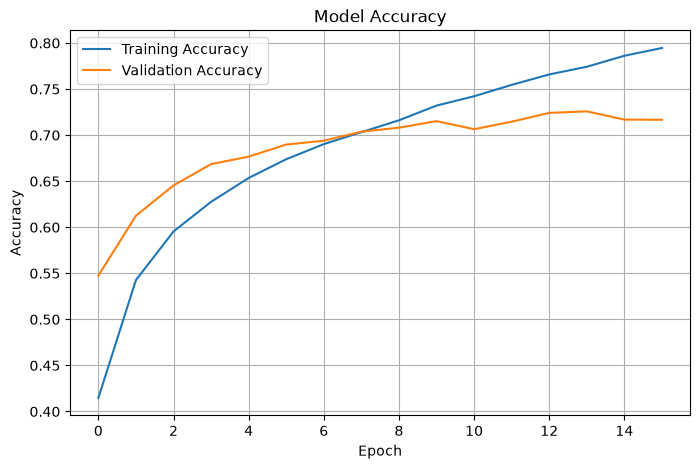

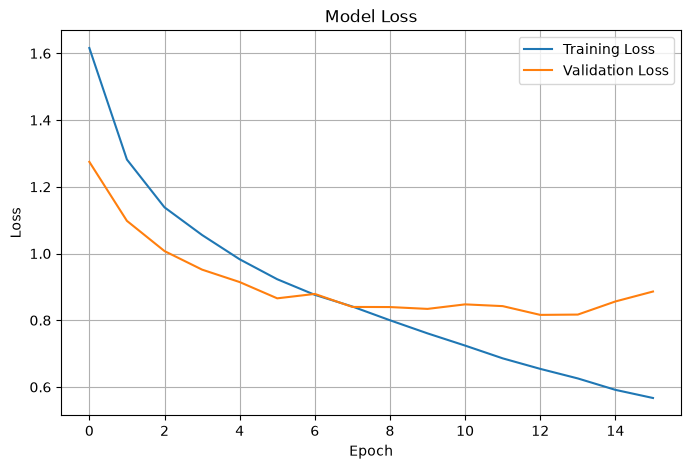

In [21]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

# Loss
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

#Confusion Matrix

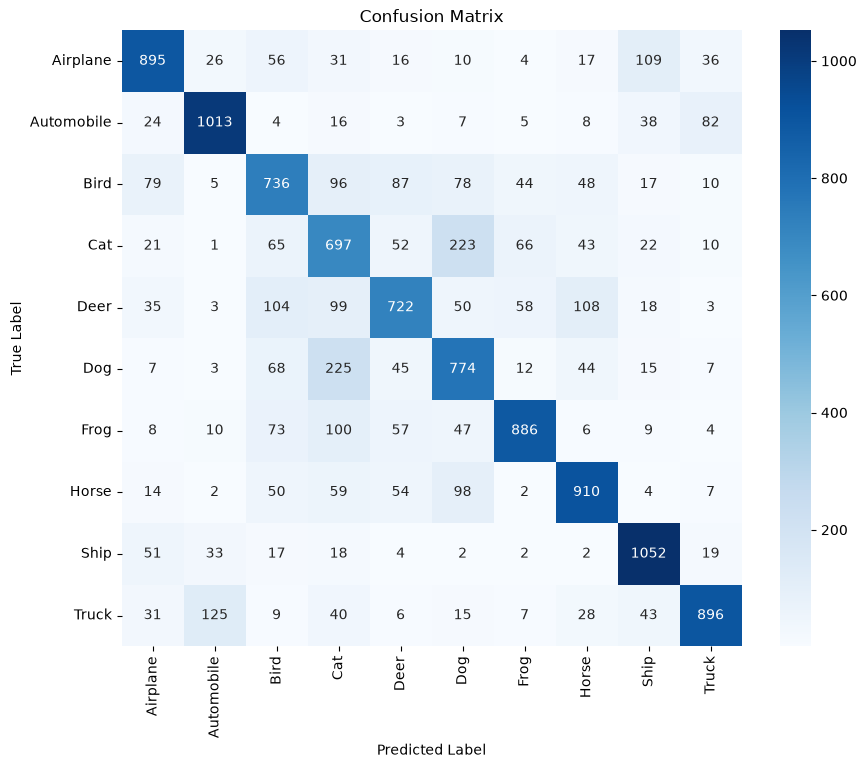

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

cm = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(10,8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()